# 51 · Domain randomization: a fixed-simulator policy vs a randomized one, on a grid of "real" pendulums

In [1]:
import time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse.rl_envs import PendulumEnv
from vlacourse.rl_algos import sac, evaluate_policy

torch.set_num_threads(4)
MASSES = [0.5, 0.7, 1.0, 1.3, 1.6, 2.0]
LENGTHS = [0.6, 0.8, 1.0, 1.2, 1.5]

def grid_eval(actor, n=3):
    G = np.zeros((len(MASSES), len(LENGTHS)))
    for i, m in enumerate(MASSES):
        for j, L in enumerate(LENGTHS):
            G[i, j] = evaluate_policy(PendulumEnv(mass=m, length=L), actor.act, n)
    return G

In [2]:
t0 = time.time()
fixed = sac(PendulumEnv(), total_steps=20_000, seed=0)
randomized = sac(PendulumEnv(randomize=dict(mass=0.3, length=0.3)), total_steps=20_000, seed=0)
print(f"trained both policies in {time.time() - t0:.0f}s")

trained both policies in 1190s


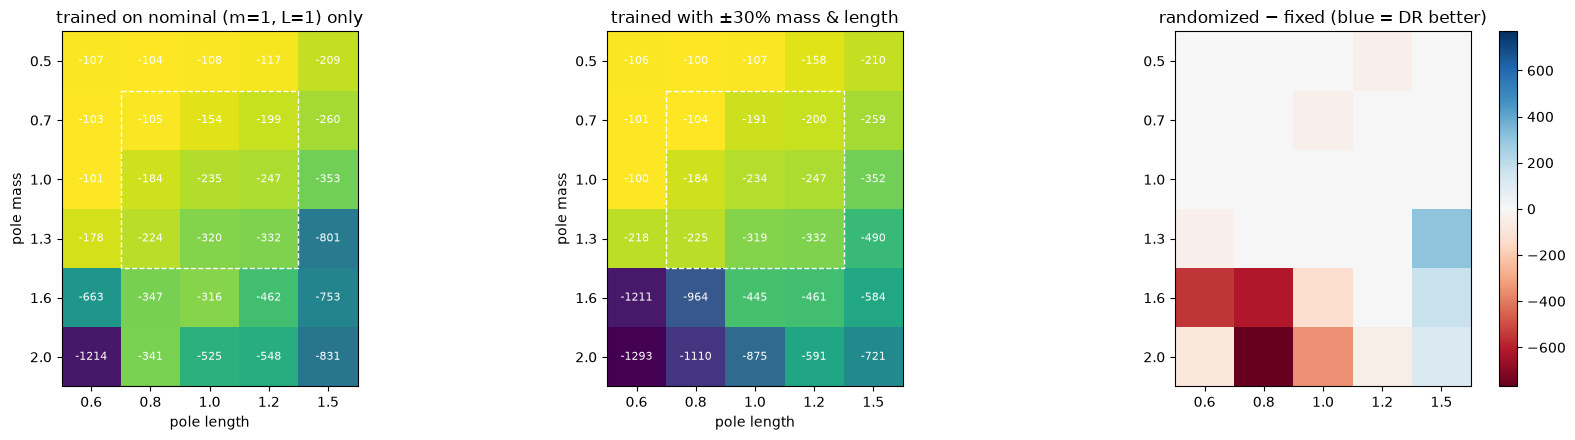

In [3]:
G_fixed, G_rand = grid_eval(fixed), grid_eval(randomized)
vmin, vmax = min(G_fixed.min(), G_rand.min()), max(G_fixed.max(), G_rand.max())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, G, title in [(axes[0], G_fixed, "trained on nominal (m=1, L=1) only"), (axes[1], G_rand, "trained with ±30% mass & length")]:
    im = ax.imshow(G, vmin=vmin, vmax=vmax, cmap="viridis")
    ax.set_xticks(range(len(LENGTHS)), LENGTHS); ax.set_yticks(range(len(MASSES)), MASSES)
    ax.set_xlabel("pole length"); ax.set_ylabel("pole mass"); ax.set_title(title)
    ax.add_patch(plt.Rectangle((0.5, 0.5), 3, 3, fill=False, ec="w", ls="--"))
    for i in range(len(MASSES)):
        for j in range(len(LENGTHS)):
            ax.text(j, i, f"{G[i, j]:.0f}", ha="center", va="center", color="w", fontsize=8)
diff = G_rand - G_fixed
im = axes[2].imshow(diff, cmap="RdBu", vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
axes[2].set_xticks(range(len(LENGTHS)), LENGTHS); axes[2].set_yticks(range(len(MASSES)), MASSES); axes[2].set_title("randomized − fixed (blue = DR better)")
plt.colorbar(im, ax=axes[2]); plt.tight_layout(); plt.show()

In [4]:
nominal = (MASSES.index(1.0), LENGTHS.index(1.0))
inside = np.zeros_like(G_fixed, bool); inside[1:4, 1:4] = True
print(f"nominal pendulum:            fixed {G_fixed[nominal]:7.0f}   randomized {G_rand[nominal]:7.0f}")
print(f"mean inside the ±30% band:   fixed {G_fixed[inside].mean():7.0f}   randomized {G_rand[inside].mean():7.0f}")
print(f"mean outside the band:       fixed {G_fixed[~inside].mean():7.0f}   randomized {G_rand[~inside].mean():7.0f}")
print(f"worst case on the grid:      fixed {G_fixed.min():7.0f}   randomized {G_rand.min():7.0f}")

nominal pendulum:            fixed    -235   randomized    -234
mean inside the ±30% band:   fixed    -222   randomized    -226
mean outside the band:       fixed    -402   randomized    -498
worst case on the grid:      fixed   -1214   randomized   -1293
